# Deep Learning HW 3 Part 3
Author: Daniel Bond

In [1]:
# Colab only: the data archive, ner_utils.py and the tokenizers from Part 2 are taken from Google Drive
from google.colab import drive
drive.mount("/content/drive")

!mkdir -p data && unzip -q -n /content/drive/MyDrive/kse-ua-location-extraction-2026.zip -d data
!cp -r /content/drive/MyDrive/ua-location-ner/ner_utils.py /content/drive/MyDrive/ua-location-ner/artifacts .
!pip install -q lightning wandb tokenizers

Mounted at /content/drive


In [2]:
import time
import urllib.request
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Optional

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader
import lightning as L
import wandb
from lightning.pytorch.callbacks import LearningRateMonitor, ModelCheckpoint
from lightning.pytorch.loggers import WandbLogger

from ner_utils import (NERDataset, Collator, load_tokenizer, load_entities, merge_touching, parse_markers,
                       label_names, make_posts, load_vectors, comp_metric, bootstrap_ci, predict_locations,
                       word_probs, word_spans, loc_probs, save_probs, gradient_norms, plot_gradient_flow,
                       make_submission)

seed = 67
L.seed_everything(seed)

DATA_DIR = Path("data")
ARTIFACTS = Path("artifacts")
# on Colab everything that has to survive a disconnect goes to Drive
OUT_DIR = Path("/content/drive/MyDrive/ua-location-ner") if Path("/content/drive").exists() else Path(".")
PRED_DIR, SUB_DIR, GRAD_DIR, CKPT_DIR, IMG_DIR = (OUT_DIR / d for d in ["preds", "subs", "grads", "checkpoints", "images"])
for d in (PRED_DIR, SUB_DIR, GRAD_DIR, CKPT_DIR, IMG_DIR):
    d.mkdir(parents=True, exist_ok=True)
RESULTS_PATH = OUT_DIR / "results.csv"

UK_TRAIN_ROWS = 500_000
RU_ROWS = 300_000
RU_TRAIN_ROWS = 100_000
RU_VALID_EVERY = 10

TYPES = ["LOC", "ORG", "PER"]
LOC_LABELS = label_names(["LOC"])
MAX_TOKENS = 256
BATCH_SIZE = {"sentences": 128, "posts": 48}
EPOCHS = 3
NUM_WORKERS = 2
PROJECT = "dl-hw3-ua-location-ner"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"torch {torch.__version__}, lightning {L.__version__}, device: {DEVICE}, outputs: {OUT_DIR.resolve()}")

INFO: Seed set to 67
INFO:lightning.fabric.utilities.seed:Seed set to 67


torch 2.14.1+cu130, lightning 2.6.6, device: cuda, outputs: /content/drive/MyDrive/ua-location-ner


## Data

In [3]:
uk_df = pd.read_csv(DATA_DIR / "uk_geo_dataset.csv")
ru_df = pd.read_csv(DATA_DIR / "ru_geo_dataset.csv", nrows=RU_ROWS)
sample_df = pd.read_csv(DATA_DIR / "labeling_sample.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")
ru_is_valid = ru_df["doc_id"] % RU_VALID_EVERY == 0

uk_train = uk_df[uk_df["is_valid"] == 0].head(UK_TRAIN_ROWS)
ru_train = ru_df[~ru_is_valid].head(RU_TRAIN_ROWS)
uk_valid = uk_df[uk_df["is_valid"] == 1]
ru_valid = ru_df[ru_is_valid]

uk_train_entities, ru_train_entities = load_entities(uk_train, TYPES), load_entities(ru_train, TYPES)
uk_posts, uk_post_entities = make_posts(uk_train["text"].tolist(), uk_train_entities, seed=seed)
ru_posts, ru_post_entities = make_posts(ru_train["text"].tolist(), ru_train_entities, seed=seed)

TRAIN_SETS = {
    "sentences": (uk_train["text"].tolist() + ru_train["text"].tolist(), uk_train_entities + ru_train_entities),
    "posts": (uk_posts + ru_posts, uk_post_entities + ru_post_entities),
}
for name, (texts, _) in TRAIN_SETS.items():
    print(f"train / {name}: {len(texts)} texts, median {int(np.median([len(t) for t in texts]))} chars, "
          f"multiline {np.mean([chr(10) in t for t in texts]):.0%}")
print("\nA pseudo-post:\n" + uk_posts[1])

train / sentences: 600000 texts, median 93 chars, multiline 0%
train / posts: 171431 texts, median 352 chars, multiline 75%

A pseudo-post:
Закликаємо всіх не вдаватися до таких відео і не розкручувати спіраль ненависті і агресії", - підсумував Шевченко.
Потім Книга пам’яті Лемківщини 1944—1946. Але про присутність іншого, неідентифікованого літака, не говориться ні слова!

Також зазначено, що до прокуратури району звернулися громадяни із заявами про те, що службові особи ПАТ "Банк Таврика" привласнили кошти, які ними були розміщенні на рахунках банку.


Two versions of the same sentences:
- `sentences` - one news sentence per example
- `posts` - 1-6 consecutive sentences glued with a space or line breaks.

Test texts are multiline posts, the sentences are short with no line breaks, so this is the cheapest way to make training data look like test data.

In [4]:
@dataclass
class EvalSet:
    name: str
    texts: List[str]
    entities: List[Dict]
    gold: List[List[str]]
    offsets: Optional[List] = None

def silver_eval_set(name, df):
    texts, entities = df["text"].tolist(), load_entities(df, TYPES)
    return EvalSet(name, texts, entities, [[t[a:b] for a, b in e["LOC"]] for t, e in zip(texts, entities)])

EVAL_SETS = [
    silver_eval_set("uk_valid", uk_valid),
    silver_eval_set("ru_valid", ru_valid),
    EvalSet("sample", sample_df["text"].tolist(),
            [{"LOC": merge_touching(parse_markers(m))} for m in sample_df["loc_markers"]],
            sample_df["locations"].map(eval).tolist()),
]
TEST_TEXTS = test_df["text"].tolist()
TOKENIZERS = {name: load_tokenizer(ARTIFACTS / f"{name}_tokenizer.json") for name in ["word", "bpe"]}

def eval_sets_for(tokenizer):
    return [EvalSet(es.name, es.texts, es.entities, es.gold, [tokenizer.encode(t)[1] for t in es.texts])
            for es in EVAL_SETS]

print({es.name: len(es.texts) for es in EVAL_SETS}, {name: tok.vocab_size for name, tok in TOKENIZERS.items()})

{'uk_valid': 10000, 'ru_valid': 30072, 'sample': 26} {'word': 100003, 'bpe': 32000}


## Model

In [5]:
class RNNEncoder(nn.Module):
    def __init__(self, vocab_size, emb_dim=128, hidden=256, num_layers=1, cell="gru", bidirectional=True,
                 dropout=0.3, embeddings=None, freeze_embeddings=False, pad_id=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_id)
        if embeddings is not None:
            self.embedding.weight.data.copy_(embeddings)
        self.embedding.weight.requires_grad = not freeze_embeddings
        self.dropout = nn.Dropout(dropout)
        rnn_class = {"gru": nn.GRU, "lstm": nn.LSTM}[cell]
        self.rnn = rnn_class(emb_dim, hidden, num_layers=num_layers, batch_first=True, bidirectional=bidirectional,
                             dropout=dropout if num_layers > 1 else 0.0)
        self.out_dim = hidden * (2 if bidirectional else 1)

    def forward(self, input_ids, lengths):
        x = self.dropout(self.embedding(input_ids))
        packed = pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.rnn(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=input_ids.shape[1])
        return self.dropout(out)

In [6]:
class LitTagger(L.LightningModule):
    def __init__(self, vocab_size, labels, eval_sets=(), embeddings=None, optimizer="adamw", lr=2e-3,
                 weight_decay=0.01, scheduler="onecycle", grad_log_every=100, **encoder_kwargs):
        super().__init__()
        self.save_hyperparameters(ignore=["eval_sets", "embeddings"])
        self.encoder = RNNEncoder(vocab_size, embeddings=embeddings, **encoder_kwargs)
        self.head = nn.Linear(self.encoder.out_dim, len(labels))
        self.loss_fn = nn.CrossEntropyLoss(ignore_index=-100)
        self.eval_sets = list(eval_sets)
        self.val_probs = {es.name: {} for es in self.eval_sets}
        self.grad_history = []

    def forward(self, input_ids, lengths):
        return self.head(self.encoder(input_ids, lengths))

    def loss(self, logits, labels):
        return self.loss_fn(logits.flatten(0, 1), labels.flatten())

    def training_step(self, batch, batch_idx):
        loss = self.loss(self(batch["input_ids"], batch["lengths"]), batch["labels"])
        self.log("train_loss", loss, prog_bar=True, batch_size=len(batch["index"]))
        return loss

    def on_after_backward(self):
        if self.global_step % self.hparams.grad_log_every == 0:
            norms = gradient_norms(self)
            self.grad_history.append({"step": self.global_step, **norms})
            self.log_dict({f"grad/{name}": norm for name, norm in norms.items()})

    def validation_step(self, batch, batch_idx, dataloader_idx=0):
        name = self.eval_sets[dataloader_idx].name
        logits = self(batch["input_ids"], batch["lengths"])
        self.log(f"val_loss/{name}", self.loss(logits, batch["labels"]), add_dataloader_idx=False,
                 batch_size=len(batch["index"]))
        probs = logits.softmax(-1).float().cpu().numpy()
        for row, i in enumerate(batch["index"].tolist()):
            self.val_probs[name][i] = probs[row, :batch["lengths"][row]]

    def on_validation_epoch_end(self):
        for es in self.eval_sets:
            probs = self.val_probs[es.name]
            idx = sorted(probs)
            pred = predict_locations([es.texts[i] for i in idx], [es.offsets[i] for i in idx],
                                     [probs[i] for i in idx], self.hparams.labels)
            self.log(f"f1/{es.name}", comp_metric([es.gold[i] for i in idx], pred), prog_bar=es.name == "uk_valid")
            self.val_probs[es.name] = {}

    def configure_optimizers(self):
        params = [p for p in self.parameters() if p.requires_grad]
        hp = self.hparams
        if hp.optimizer == "adamw":
            optimizer = torch.optim.AdamW(params, lr=hp.lr, weight_decay=hp.weight_decay)
        elif hp.optimizer == "adam":
            optimizer = torch.optim.Adam(params, lr=hp.lr)
        elif hp.optimizer == "rmsprop":
            optimizer = torch.optim.RMSprop(params, lr=hp.lr)
        else:
            optimizer = torch.optim.SGD(params, lr=hp.lr, momentum=0.9, nesterov=True)

        steps = self.trainer.estimated_stepping_batches
        if hp.scheduler == "onecycle":
            scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=hp.lr, total_steps=steps, pct_start=0.1)
        elif hp.scheduler == "cosine":
            scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=steps)
        elif hp.scheduler == "plateau":
            scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.3, patience=0)
            return {"optimizer": optimizer,
                    "lr_scheduler": {"scheduler": scheduler, "monitor": "f1/uk_valid", "interval": "epoch",
                                     "strict": False}}
        else:
            return optimizer
        return {"optimizer": optimizer, "lr_scheduler": {"scheduler": scheduler, "interval": "step"}}


@torch.no_grad()
def predict_word_probs(model, tokenizer, texts, batch_size=256):
    model.eval().to(DEVICE)
    dataset = NERDataset(texts, tokenizer)
    out = [None] * len(texts)
    for batch in DataLoader(dataset, batch_size=batch_size, collate_fn=Collator()):
        probs = model(batch["input_ids"].to(DEVICE), batch["lengths"]).softmax(-1).float().cpu().numpy()
        for row, i in enumerate(batch["index"].tolist()):
            offsets = dataset[i]["offsets"]
            _, per_word = word_probs(texts[i], offsets, probs[row, :len(offsets)])
            out[i] = loc_probs(per_word, model.hparams.labels)
    return out

- `RNNEncoder`: embedding -> dropout -> GRU or LSTM (uni/bidirectional, 1+ layers) over packed sequences -> dropout
- `LitTagger`: a linear layer over the encoder output gives BIO logits per token
- `predict_word_probs`: predictions are stored per word (first subword for BPE) as O / B-LOC / I-LOC

## Adversarial validation

In [ ]:
class LitAdversarial(L.LightningModule):
    def __init__(self, vocab_size, lr=2e-3, **encoder_kwargs):
        super().__init__()
        self.save_hyperparameters()
        self.encoder = RNNEncoder(vocab_size, **encoder_kwargs)
        self.head = nn.Linear(self.encoder.out_dim, 1)
        self.loss_fn = nn.BCEWithLogitsLoss()

    def forward(self, input_ids, lengths):
        hidden = self.encoder(input_ids, lengths)
        pooled = hidden.sum(1) / lengths.to(hidden.device).unsqueeze(1)
        return self.head(pooled).squeeze(1)

    def training_step(self, batch, batch_idx):
        loss = self.loss_fn(self(batch["input_ids"], batch["lengths"]), batch["target"])
        self.log("adv_train_loss", loss, prog_bar=True, batch_size=len(batch["index"]))
        return loss

    def predict_step(self, batch, batch_idx):
        return torch.sigmoid(self(batch["input_ids"], batch["lengths"])).float().cpu()

    def configure_optimizers(self):
        return torch.optim.AdamW(self.parameters(), lr=self.hparams.lr)


ADV_ENCODER = dict(emb_dim=128, hidden=256, num_layers=1, cell="gru", bidirectional=True, dropout=0.3)
target_texts = TEST_TEXTS + sample_df["text"].tolist()


def adversarial_auc(name, source_texts, n_source=5000, epochs=3):
    L.seed_everything(seed)
    rng = np.random.default_rng(seed)
    source = [source_texts[i] for i in rng.choice(len(source_texts), min(n_source, len(source_texts)), replace=False)]
    texts, y = source + target_texts, [0.0] * len(source) + [1.0] * len(target_texts)
    train_texts, valid_texts, train_y, valid_y = train_test_split(texts, y, test_size=0.3, stratify=y, random_state=seed)

    tokenizer = TOKENIZERS["bpe"]
    train_dl = DataLoader(NERDataset(train_texts, tokenizer, targets=train_y, max_tokens=MAX_TOKENS),
                          batch_size=64, shuffle=True, collate_fn=Collator())
    valid_dl = DataLoader(NERDataset(valid_texts, tokenizer, targets=valid_y, max_tokens=MAX_TOKENS),
                          batch_size=256, collate_fn=Collator())
    model = LitAdversarial(tokenizer.vocab_size, **ADV_ENCODER)
    logger = WandbLogger(project=PROJECT, name=f"adv_{name}", group="adversarial", save_dir=OUT_DIR)
    trainer = L.Trainer(max_epochs=epochs, accelerator="auto", devices=1, logger=logger,
                        enable_checkpointing=False, gradient_clip_val=1.0, log_every_n_steps=10)
    trainer.fit(model, train_dl)
    probs = torch.cat(trainer.predict(model, valid_dl)).numpy()
    auc = roc_auc_score(valid_y, probs)
    logger.experiment.summary["adv_auc"] = auc
    wandb.finish()
    return {"AUC": auc, "mean P(test) on news": probs[np.array(valid_y) == 0].mean(),
            "mean P(test) on test": probs[np.array(valid_y) == 1].mean()}


adv = pd.DataFrame({name: adversarial_auc(name, TRAIN_SETS[name][0]) for name in ["sentences", "posts"]}).T
adv.round(4)

INFO: Seed set to 67
INFO:lightning.fabric.utilities.seed:Seed set to 67
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
wandb: WARNING The anonymous setting has no effect and will be removed in a future version.
/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191:

wandb: Enter your choice: 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: dbond (dbond-kse) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


... (13 outputs left out)

INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Output()

adv_train_loss,▅█▄▅▇▅▅▂▃▂▃▄▂▄▂▂▂▁
epoch,▁▁▁▁▁▁▅▅▅▅▅▅██████
trainer/global_step,▁▁▂▂▃▃▃▄▄▅▅▆▆▆▇▇██
adv_auc,0.96956
adv_train_loss,0.01389
epoch,2
trainer/global_step,179


,AUC,mean P(test) on news,mean P(test) on test
sentences,0.9900,0.0096,0.9140
posts,0.9696,0.0159,0.7763


Adversarial validation results:
- News sentences vs test: AUC 0.990
- Pseudo-posts vs test: AUC 0.970

Combining sentences removes the most obvious differences, but the classifier still confidently separates the two. The shift is large, so local validation won't represent the LB, and the parameter tunings will rely on submission scores rather than local.

## Experiments

In [7]:
BASE = dict(emb_dim=128, hidden=256, num_layers=1, cell="gru", bidirectional=True, dropout=0.3,
            optimizer="adamw", lr=2e-3, weight_decay=0.01, scheduler="onecycle")

def run_experiment(name, tokenizer="bpe", data="sentences", types=TYPES, embeddings=None, epochs=EPOCHS, **overrides):
    if (PRED_DIR / f"{name}.npz").exists():
        print(f"{name}: already done")
        return
    L.seed_everything(seed)
    config = {**BASE, **overrides}
    tok = TOKENIZERS[tokenizer]
    texts, entities = TRAIN_SETS[data]
    eval_sets = eval_sets_for(tok)
    train_dl = DataLoader(NERDataset(texts, tok, types, entities, max_tokens=MAX_TOKENS), batch_size=BATCH_SIZE[data],
                          shuffle=True, collate_fn=Collator(), num_workers=NUM_WORKERS)
    val_dls = [DataLoader(NERDataset(es.texts, tok, types, es.entities), batch_size=256, collate_fn=Collator())
               for es in eval_sets]

    model = LitTagger(tok.vocab_size, label_names(types), eval_sets, embeddings=embeddings, **config)
    logger = WandbLogger(project=PROJECT, name=name, save_dir=OUT_DIR,
                         config={"tokenizer": tokenizer, "data": data, "types": types, "epochs": epochs,
                                 "pretrained_embeddings": embeddings is not None})
    ckpt = ModelCheckpoint(dirpath=CKPT_DIR, filename=name, monitor="f1/uk_valid", mode="max",
                           save_weights_only=True, enable_version_counter=False)
    trainer = L.Trainer(max_epochs=epochs, accelerator="auto", devices=1,
                        precision="16-mixed" if DEVICE == "cuda" else "32-true",
                        logger=logger, callbacks=[ckpt, LearningRateMonitor("step")],
                        gradient_clip_val=1.0, val_check_interval=0.5, num_sanity_val_steps=0, log_every_n_steps=50)
    start = time.time()
    trainer.fit(model, train_dl, val_dls)
    minutes = (time.time() - start) / 60

    model.load_state_dict(torch.load(ckpt.best_model_path, weights_only=False)["state_dict"])
    probs = {es.name: predict_word_probs(model, tok, es.texts) for es in eval_sets}
    probs["test"] = predict_word_probs(model, tok, TEST_TEXTS)
    save_probs(PRED_DIR / f"{name}.npz", probs)
    pd.DataFrame(model.grad_history).to_csv(GRAD_DIR / f"{name}.csv", index=False)

    row = {"name": name, "tokenizer": tokenizer, "data": data, "labels": "+".join(types), **config,
           "pretrained": embeddings is not None, "params_M": sum(p.numel() for p in model.parameters()) / 1e6,
           "minutes": minutes}
    for es in eval_sets:
        pred = predict_locations(es.texts, [word_spans(t) for t in es.texts], probs[es.name], LOC_LABELS)
        row[f"f1_{es.name}"] = comp_metric(es.gold, pred)
        if es.name == "sample":
            row["sample_ci_low"], row["sample_ci_high"] = bootstrap_ci(es.gold, pred)
    test_pred = predict_locations(TEST_TEXTS, [word_spans(t) for t in TEST_TEXTS], probs["test"], LOC_LABELS)
    make_submission(test_df, test_pred, SUB_DIR / f"{name}.csv")
    row["test_locations"] = sum(map(len, test_pred))

    logger.experiment.summary.update({k: v for k, v in row.items() if k.startswith(("f1_", "sample_ci"))})
    wandb.finish()
    results = pd.read_csv(RESULTS_PATH) if RESULTS_PATH.exists() else pd.DataFrame()
    pd.concat([results, pd.DataFrame([row])], ignore_index=True).to_csv(RESULTS_PATH, index=False)

def show_results(prefixes=None):
    results = pd.read_csv(RESULTS_PATH)
    if prefixes:
        results = results[results["name"].str.startswith(tuple(prefixes))]
    columns = ["name", "tokenizer", "data", "labels", "cell", "num_layers", "bidirectional", "hidden", "optimizer",
               "scheduler", "params_M", "minutes", "f1_uk_valid", "f1_ru_valid", "f1_sample", "sample_ci_low",
               "sample_ci_high", "test_locations"]
    return results[columns].set_index("name").round(4)

### Direction and tokenization

In [ ]:
run_experiment("01_gru_word", tokenizer="word", bidirectional=False)
run_experiment("02_bigru_word", tokenizer="word")
run_experiment("03_bigru_bpe")
show_results(["01", "02", "03"])

INFO: Seed set to 67
INFO:lightning.fabric.utilities.seed:Seed set to 67
INFO: Using 16bit Automatic Mixed Precision (AMP)
INFO:lightning.pytorch.utilities.rank_zero:Using 16bit Automatic Mixed Precision (AMP)
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
wandb: W&B API key is c

INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: Loading `train_dataloader` to estimate number of stepping batches.
INFO:lightning.pytorch.utilities.rank_zero:Loading `train_dataloader` to estimate number of stepping batches.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ encoder │ RNNEncoder       │ 13.1 M │ train │     0 │
│ 1 │ head    │ Linear           │  1.8 K │ train │     0 │
│ 2 │ loss_fn │ CrossEntropyLoss │      0 │ train │     0 │
└───┴─────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 13.1 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 13.1 M                                                                                               
Total estimated model params size (MB): 52.395                                                                     
Modules in train mode: 6                                                                                           
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

INFO: `Trainer.fit` stopped: `max_epochs=3` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=3` reached.


... (12 outputs left out)

Output()

INFO: `Trainer.fit` stopped: `max_epochs=3` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=3` reached.


epoch,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▅▅▅▅▅▅▅▅▅▅▅▅█████████████
f1/ru_valid,▁▅▇███
f1/sample,▁▄▇▆██
f1/uk_valid,▁▅▇███
grad/encoder.embedding.weight,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▁▂▂▂▃▃▃▃▂▂▂▄▃▄▄▅▆▃▄█▇▇▆▃
grad/encoder.rnn.bias_hh_l0,▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▁▂▁▂▂▂▂▃▂▂▃▂▂▂▄▄▃▄█▅▃
grad/encoder.rnn.bias_hh_l0_reverse,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▁▂▂▂▃▂▃▃▃▃▄▅▅▅▃▃
grad/encoder.rnn.bias_ih_l0,▃▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▁▁▁▂▂▂▂▂▂▃▂▂▂▃▂▅▃▃▃▃█▅▃
grad/encoder.rnn.bias_ih_l0_reverse,▁▁▁▁▁▁▁▁▁▁▁▂▁▂▂▂▂▂▂▂▂▂▃▂▂▃▃▂▂▆▃▅▄▅▆█▆▅▅▄
grad/encoder.rnn.weight_hh_l0,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▂▁▂▂▂▂▂▃▃▂▂▂▃▂▃▅▄▄▃▅█▇▄▄
+11,...


,tokenizer,data,labels,cell,num_layers,bidirectional,hidden,optimizer,scheduler,params_M,minutes,f1_uk_valid,f1_ru_valid,f1_sample,sample_ci_low,sample_ci_high,test_locations
name,,,,,,,,,,,,,,,,,
01_gru_word,word,sentences,LOC+ORG+PER,gru,1,False,256,adamw,onecycle,13.0986,11.1209,0.8449,0.8822,0.4500,0.2623,0.6265,852
02_bigru_word,word,sentences,LOC+ORG+PER,gru,1,True,256,adamw,onecycle,13.3969,12.0423,0.8729,0.9122,0.4878,0.3158,0.6757,860
03_bigru_bpe,bpe,sentences,LOC+ORG+PER,gru,1,True,256,adamw,onecycle,4.6925,16.8084,0.8798,0.9281,0.6190,0.4680,0.7359,858


- Direction: bidirectional wins
- Tokenization: BPE gives better scores with less parameters

BPE + bidirectional is the base for the next blocks.

### Depth and cell type

In [ ]:
run_experiment("04_bigru2_bpe", num_layers=2)
run_experiment("05_bilstm_bpe", cell="lstm")
run_experiment("06_bilstm2_bpe", num_layers=2, cell="lstm")
show_results(["03", "04", "05", "06"])

Epoch 2/2  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4688/4688 0:06:28 • 0:00:00 13.05it/s v_num: 92nw train_loss: 0.036    
                                                                                  f1/uk_valid: 0.880               

INFO: `Trainer.fit` stopped: `max_epochs=3` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=3` reached.


epoch,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▅▅▅▅▅▅▅▅▅▅▅▅▅▅███████████
f1/ru_valid,▁▅▇▇██
f1/sample,▃▇▁▆██
f1/uk_valid,▁▅▇▇██
grad/encoder.embedding.weight,▁▁▁▁▁▁▁▁▁▁▁▁▂▁▁▁▂▂▁▂▂▂▂▂▂▃▃▄▃▃▄▄█▇▅▇▆▄▄▆
grad/encoder.rnn.bias_hh_l0,▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▂▂▁▁▃▃▄▂▂▃▃▂▄▃▃▄▅▄▇▅█▇
grad/encoder.rnn.bias_hh_l0_reverse,▂▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▃▂▁▂▂▂▂▃▃▃▂▃▃▃▃▃▅█▆▅
grad/encoder.rnn.bias_hh_l1,▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▁▂▂▂▂▂▂▂▂▂▂▄▆▄▅▃█▆▇▇▇
grad/encoder.rnn.bias_hh_l1_reverse,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▂▁▁▁▂▂▂▂▂▃▂▂▂▃▂▂▂▂▄▅▆▆█
grad/encoder.rnn.bias_ih_l0,▁▁▁▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▂▁▂▂▂▂▂▃▃▃▂▄▃▃▃▃▄▅▅█▆▃
+19,...


,tokenizer,data,labels,cell,num_layers,bidirectional,hidden,optimizer,scheduler,params_M,minutes,f1_uk_valid,f1_ru_valid,f1_sample,sample_ci_low,sample_ci_high,test_locations
name,,,,,,,,,,,,,,,,,
03_bigru_bpe,bpe,sentences,LOC+ORG+PER,gru,1,True,256,adamw,onecycle,4.6925,16.8084,0.8798,0.9281,0.6190,0.4680,0.7359,858
04_bigru2_bpe,bpe,sentences,LOC+ORG+PER,gru,2,True,256,adamw,onecycle,5.8752,19.4350,0.8847,0.9289,0.5977,0.4415,0.7273,943
05_bilstm_bpe,bpe,sentences,LOC+ORG+PER,lstm,1,True,256,adamw,onecycle,4.8901,18.1819,0.8817,0.9327,0.6341,0.4706,0.7750,891
06_bilstm2_bpe,bpe,sentences,LOC+ORG+PER,lstm,2,True,256,adamw,onecycle,6.4671,20.4902,0.8870,0.9357,0.6329,0.4675,0.7664,847


- Depth: the second layer adds a little bit to score for only 2-3 more minutes of training
- Cell: LSTM is ahead of GRU at both depths, though it has ~10% more parameters in the recurrent part

Differences here are small, 2-layer BiLSTM (06) is the best on valid and is used as the base for the embedding and optimizer blocks.

### Training data: pseudo-posts and label set

In [ ]:
run_experiment("07_bigru2_bpe_posts", num_layers=2, data="posts")
run_experiment("08_bilstm2_bpe_posts", num_layers=2, cell="lstm", data="posts")
run_experiment("09_bigru2_bpe_posts_loc", num_layers=2, data="posts", types=["LOC"])
show_results(["04", "06", "07", "08", "09"])

Epoch 2/2  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3572/3572 0:05:36 • 0:00:00 11.51it/s v_num: rzsj train_loss: 0.010    
                                                                                  f1/uk_valid: 0.869               

INFO: `Trainer.fit` stopped: `max_epochs=3` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=3` reached.


epoch,▁▁▁▁▁▁▁▁▁▁▁▁▅▅▅▅▅▅▅▅▅▅▅▅▅███████████████
f1/ru_valid,▁▄▇▇██
f1/sample,█▁▃▇█▃
f1/uk_valid,▁▄▆▇██
grad/encoder.embedding.weight,▁▁▁▁▁▁▁▁▂▂▁▂▂▂▂▂▂▂▃▂▂▃▄▃▃▄▄▄▅▅▅▅▄▅▃▃▄█▇▅
grad/encoder.rnn.bias_hh_l0,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▁▁▁▁▂▂▂▂▂▂▃▃▂▄▃▄▄▃▃▃▂▃██▄
grad/encoder.rnn.bias_hh_l0_reverse,▁▁▁▁▁▁▁▁▁▁▁▁▁▂▁▂▁▂▁▁▁▁▁▁▁▂▂▃▃▂▃▃▄▃▃▃▅▄▃█
grad/encoder.rnn.bias_hh_l1,▁▁▂▂▁▁▁▁▁▁▁▁▁▁▂▂▂▂▂▂▂▂▁▂▂▃▄▃▂▂▂▃▃▄▄▅▅▃█▅
grad/encoder.rnn.bias_hh_l1_reverse,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
grad/encoder.rnn.bias_ih_l0,▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▁▂▁▁▂▃▃▂▃▂▃▃▃▃▃▆▄█▄▅
+19,...


,tokenizer,data,labels,cell,num_layers,bidirectional,hidden,optimizer,scheduler,params_M,minutes,f1_uk_valid,f1_ru_valid,f1_sample,sample_ci_low,sample_ci_high,test_locations
name,,,,,,,,,,,,,,,,,
04_bigru2_bpe,bpe,sentences,LOC+ORG+PER,gru,2,True,256,adamw,onecycle,5.8752,19.4350,0.8847,0.9289,0.5977,0.4415,0.7273,943
06_bilstm2_bpe,bpe,sentences,LOC+ORG+PER,lstm,2,True,256,adamw,onecycle,6.4671,20.4902,0.8870,0.9357,0.6329,0.4675,0.7664,847
07_bigru2_bpe_posts,bpe,posts,LOC+ORG+PER,gru,2,True,256,adamw,onecycle,5.8752,18.1474,0.8810,0.9271,0.5789,0.4615,0.7213,867
08_bilstm2_bpe_posts,bpe,posts,LOC+ORG+PER,lstm,2,True,256,adamw,onecycle,6.4671,18.5644,0.8856,0.9334,0.5897,0.4444,0.7797,845
09_bigru2_bpe_posts_loc,bpe,posts,LOC,gru,2,True,256,adamw,onecycle,5.8732,17.7075,0.8763,0.9335,0.5789,0.4411,0.7576,833


- Pseudo-posts did not help on validation (it is single sentences, so a model trained on sentences has an advantage there)
- LOC-only labels (09) are worse than LOC + ORG + PER (07)

Since posts gave nothing on validation, the next blocks train on sentences. Later public LB submissions showed that this was a mistake, and pseudo-posts have advantage on test set.

### Pretrained fastText embeddings

In [ ]:
FASTTEXT_PATH = ARTIFACTS / "cc.uk.300.vec.gz"
if not FASTTEXT_PATH.exists():
    urllib.request.urlretrieve("https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.uk.300.vec.gz", FASTTEXT_PATH)

word_vocab = TOKENIZERS["word"].itos
fasttext_matrix, in_fasttext = load_vectors(FASTTEXT_PATH, word_vocab)
print(f"word vocabulary covered by fastText: {in_fasttext.mean():.1%}; "
      f"not covered: {[w for w, f in zip(word_vocab, in_fasttext) if not f][3:15]}")

word300 = dict(tokenizer="word", emb_dim=300, num_layers=2, cell="lstm")  # 06_bilstm2_bpe with word-level 300-d embeddings
run_experiment("10_bilstm2_word", **word300)
run_experiment("11_bilstm2_word_fasttext", **word300, embeddings=fasttext_matrix)
run_experiment("12_bilstm2_word_fasttext_frozen", **word300, embeddings=fasttext_matrix, freeze_embeddings=True)
show_results(["06", "10", "11", "12"])

INFO: Seed set to 67
INFO:lightning.fabric.utilities.seed:Seed set to 67


word vocabulary covered by fastText: 94.4%; not covered: ['COVID-19', "здоров'я", 'здоров’я', "зв'язку", 'зв’язку', "п'ять", "інтерв'ю", 'п’ять', '`', 'сім’ї', 'обов’язково', 'Covid-19']


INFO: Using 16bit Automatic Mixed Precision (AMP)
INFO:lightning.pytorch.utilities.rank_zero:Using 16bit Automatic Mixed Precision (AMP)
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/loggers/wandb.py:400: There is a wandb

┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ encoder │ RNNEncoder       │ 32.7 M │ train │     0 │
│ 1 │ head    │ Linear           │  3.6 K │ train │     0 │
│ 2 │ loss_fn │ CrossEntropyLoss │      0 │ train │     0 │
└───┴─────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 32.7 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 32.7 M                                                                                               
Total estimated model params size (MB): 130.897                                                                    
Modules in train mode: 6                                                                                           
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

... (13 outputs left out)

Output()

INFO: `Trainer.fit` stopped: `max_epochs=3` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=3` reached.


epoch,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▅▅▅▅▅▅▅▅▅▅▅▅▅▅▅▅▅████████
f1/ru_valid,▁▅▇▇██
f1/sample,▁█▇▆▅▅
f1/uk_valid,▁▅▆███
grad/encoder.rnn.bias_hh_l0,▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▁▁▁▁▂▂▂▂▂▂▂▂▃▂▂▃▄█▃▄▄▄
grad/encoder.rnn.bias_hh_l0_reverse,▂▁▁▂▁▁▁▁▁▂▁▁▁▂▁▁▂▂▂▂▂▂▃▂▄▂▃▅▄█▃▃▃▇▄▆▃▄▄▄
grad/encoder.rnn.bias_hh_l1,▁▁▁▁▂▁▁▁▁▁▁▁▁▁▁▂▁▁▁▂▂▂▂▂▂▂▂▃▂▃▃▃▄▄█▄▃▅▄▃
grad/encoder.rnn.bias_hh_l1_reverse,▇▁▁▂▁▁▁▁▁▁▁▁▂▁▁▁▁▁▂▂▂▂▂▁▂▂▃▃▂▃▄▄▄▄▃█▃▄▄▃
grad/encoder.rnn.bias_ih_l0,▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▂▂▂▂▃▃▄▄▄▃▃▃▃█▄▄▄▃▃
grad/encoder.rnn.bias_ih_l0_reverse,▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▂▂▃▃▃▂▄▄▆█▇▄▄▅▄▆▄▄▅▅▃
+18,...


,tokenizer,data,labels,cell,num_layers,bidirectional,hidden,optimizer,scheduler,params_M,minutes,f1_uk_valid,f1_ru_valid,f1_sample,sample_ci_low,sample_ci_high,test_locations
name,,,,,,,,,,,,,,,,,
06_bilstm2_bpe,bpe,sentences,LOC+ORG+PER,lstm,2,True,256,adamw,onecycle,6.4671,20.4902,0.8870,0.9357,0.6329,0.4675,0.7664,847
10_bilstm2_word,word,sentences,LOC+ORG+PER,lstm,2,True,256,adamw,onecycle,32.7242,16.3911,0.8788,0.9287,0.6494,0.5151,0.7797,829
11_bilstm2_word_fasttext,word,sentences,LOC+ORG+PER,lstm,2,True,256,adamw,onecycle,32.7242,16.1582,0.8893,0.9421,0.5205,0.3636,0.7170,795
12_bilstm2_word_fasttext_frozen,word,sentences,LOC+ORG+PER,lstm,2,True,256,adamw,onecycle,32.7242,14.1731,0.8782,0.9198,0.6176,0.4722,0.7761,750


Three models: trained from scratch (10), initialized with fastText `cc.uk.300` and fine-tuned (11), fastText frozen (12)

- Fine-tuned fastText is the best on valid, on the sample it is the worst of them
- Frozen fastText is equal to training from scratch on `uk_valid` and loses on Russian
- Compared with BPE the fastText model is not better and has 5x more parameters

### Optimizers, schedulers, size

In [16]:
best = dict(num_layers=2, cell="lstm")  # 06_bilstm2_bpe: best on silver validation, trained on sentences
run_experiment("13_bilstm2_bpe_adam_const", **best, optimizer="adam", lr=1e-3, scheduler="none")
run_experiment("14_bilstm2_bpe_adam_plateau", **best, optimizer="adam", lr=2e-3, scheduler="plateau")
run_experiment("17_bilstm2_bpe_h384_d05", **best, hidden=384, dropout=0.5)
run_experiment("18_bilstm2_bpe_lr5e-3", **best, lr=5e-3)
show_results(["06", "13", "14", "17", "18"])

13_bilstm2_bpe_adam_const: already done
14_bilstm2_bpe_adam_plateau: already done
17_bilstm2_bpe_h384_d05: already done
18_bilstm2_bpe_lr5e-3: already done


,tokenizer,data,labels,cell,num_layers,bidirectional,hidden,optimizer,scheduler,params_M,minutes,f1_uk_valid,f1_ru_valid,f1_sample,sample_ci_low,sample_ci_high,test_locations
name,,,,,,,,,,,,,,,,,
06_bilstm2_bpe,bpe,sentences,LOC+ORG+PER,lstm,2,True,256,adamw,onecycle,6.4671,20.4902,0.8870,0.9357,0.6329,0.4675,0.7664,847
13_bilstm2_bpe_adam_const,bpe,sentences,LOC+ORG+PER,lstm,2,True,256,adam,none,6.4671,19.1005,0.8890,0.9344,0.6154,0.4415,0.7576,848
14_bilstm2_bpe_adam_plateau,bpe,sentences,LOC+ORG+PER,lstm,2,True,256,adam,plateau,6.4671,19.4258,0.8888,0.9404,0.6667,0.4946,0.8056,866
17_bilstm2_bpe_h384_d05,bpe,sentences,LOC+ORG+PER,lstm,2,True,384,adamw,onecycle,9.2255,19.7553,0.8752,0.9175,0.6341,0.4770,0.7647,893
18_bilstm2_bpe_lr5e-3,bpe,sentences,LOC+ORG+PER,lstm,2,True,256,adamw,onecycle,6.4671,19.4609,0.8955,0.9409,0.6750,0.5135,0.8182,835


06 (AdamW, OneCycle, lr 2e-3) is the reference for these runs

- Learning rate: OneCycle with max lr 5e-3 (18) is the best run of the whole grid
- Adam with a constant lr 1e-3 (13) and Adam with ReduceLROnPlateau (14) reach the same level as the reference.
- A larger model with more dropout is worse
- Failed: SGD - the worst case of all runs, lower on valid than all other models, and on sample is the only one to consistently go down in score.

### Combined configuration

The public LB agrees with validation on two things: LSTM is the best encoder and the learning rate of 5e-3 is the best optimizer setting. On pseudo-posts it disagrees with validation, they are better on the LB. 

The last run: BiLSTM x2, BPE, posts, lr 5e-3.

In [8]:
run_experiment("19_bilstm2_bpe_posts_lr5e-3", num_layers=2, cell="lstm", data="posts", lr=5e-3)
show_results(["06", "08", "18", "19"])

INFO: Seed set to 67
INFO:lightning.fabric.utilities.seed:Seed set to 67
INFO: Using 16bit Automatic Mixed Precision (AMP)
INFO:lightning.pytorch.utilities.rank_zero:Using 16bit Automatic Mixed Precision (AMP)
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
wandb: WARNING The anon

wandb: Enter your choice: 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: dbond (dbond-kse) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/callbacks/model_checkpoint.py:881: Checkpoint directory /content/drive/MyDrive/ua-location-ner/checkpoints exists and is not empty.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: Loading `train_dataloader` to estimate number of stepping batches.
INFO:lightning.pytorch.utilities.rank_zero:Loading `train_dataloader` to estimate number of stepping batches.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


... (2 outputs left out)

Output()

INFO: `Trainer.fit` stopped: `max_epochs=3` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=3` reached.


epoch,▁▁▁▁▁▁▁▁▁▁▁▁▅▅▅▅▅▅▅▅▅▅▅▅▅███████████████
f1/ru_valid,▁▅▆▇██
f1/sample,▁▇▇▇█▇
f1/uk_valid,▁▄▆▆▇█
grad/encoder.embedding.weight,▁▁▁▁▁▁▁▁▁▁▂▂▂▂▁▂▂▂▂▂▂▂▂▃▃▃▃▃▃▃▃▂▃▃▃▄▇▄▅█
grad/encoder.rnn.bias_hh_l0,▆▁▁▂▂▁▁▁▁▁▁▁▁▁▁▂▂▂▂▂▁▂▂▂▂▂▂▂▄▃▃▅▄▃▃▄▆▇▇█
grad/encoder.rnn.bias_hh_l0_reverse,▇▁▂▂▁▁▁▂▂▂▁▁▁▂▁▂▂▂▃▃▃▃▂▂▂▂▂▃▄▄▄▄▅▅▄▃▃▄█▇
grad/encoder.rnn.bias_hh_l1,▂▂▁▁▁▁▂▁▁▂▁▃▂▂▂▂▂▂▂▂▂▃▄▃▃▂▄▄▅▃▄▄▄▄▄▇▇▇▇█
grad/encoder.rnn.bias_hh_l1_reverse,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▂▂▂▂▂▂
grad/encoder.rnn.bias_ih_l0,▁▂▂▁▁▁▂▁▁▁▂▁▁▁▁▂▂▃▃▁▂▂▁▃▂▃▃▂▂▅▄▄▅▄▄▄▅▃▄█
+19,...


,tokenizer,data,labels,cell,num_layers,bidirectional,hidden,optimizer,scheduler,params_M,minutes,f1_uk_valid,f1_ru_valid,f1_sample,sample_ci_low,sample_ci_high,test_locations
name,,,,,,,,,,,,,,,,,
06_bilstm2_bpe,bpe,sentences,LOC+ORG+PER,lstm,2,True,256,adamw,onecycle,6.4671,20.4902,0.8870,0.9357,0.6329,0.4675,0.7664,847
08_bilstm2_bpe_posts,bpe,posts,LOC+ORG+PER,lstm,2,True,256,adamw,onecycle,6.4671,18.5644,0.8856,0.9334,0.5897,0.4444,0.7797,845
18_bilstm2_bpe_lr5e-3,bpe,sentences,LOC+ORG+PER,lstm,2,True,256,adamw,onecycle,6.4671,19.4609,0.8955,0.9409,0.6750,0.5135,0.8182,835
19_bilstm2_bpe_posts_lr5e-3,bpe,posts,LOC+ORG+PER,lstm,2,True,256,adamw,onecycle,6.4671,20.0107,0.8885,0.9401,0.6316,0.4923,0.8077,840


The combination is not better locally. On the LB it's also worse. 

The gain from posts seen on the LB did not carry over to the higher learning rate, so run 18 stays the best single model.

### Training curves

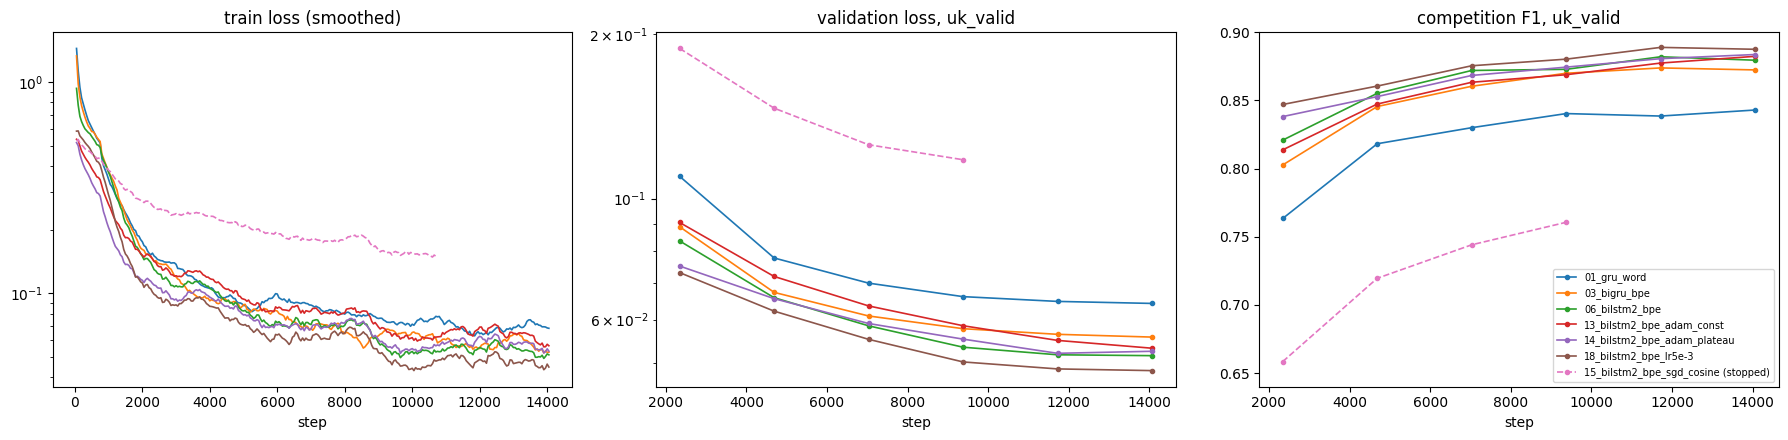

In [ ]:
import matplotlib.pyplot as plt

CURVE_RUNS = ["01_gru_word", "03_bigru_bpe", "06_bilstm2_bpe", "13_bilstm2_bpe_adam_const",
              "14_bilstm2_bpe_adam_plateau", "18_bilstm2_bpe_lr5e-3", "15_bilstm2_bpe_sgd_cosine"]
METRICS = {"train_loss": "train loss (smoothed)", "val_loss/uk_valid": "validation loss, uk_valid",
           "f1/uk_valid": "competition F1, uk_valid"}

api = wandb.Api()
runs = {run.name: run for run in api.runs(f"{api.default_entity}/{PROJECT}") if run.name in CURVE_RUNS}

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for name in CURVE_RUNS:
    for ax, (key, title) in zip(axes, METRICS.items()):
        history = runs[name].history(keys=[key], x_axis="trainer/global_step", samples=600, pandas=True)
        if name.startswith("15"):
            restart = history["trainer/global_step"].diff().lt(0)
            history = history[~restart.cummax()]
        values = history[key].rolling(15, min_periods=1).mean() if key == "train_loss" else history[key]
        ax.plot(history["trainer/global_step"], values, lw=1.2, marker=None if key == "train_loss" else "o", ms=3,
                ls="--" if name.startswith("15") else "-", label=name + (" (stopped)" if name.startswith("15") else ""))
        ax.set(title=title, xlabel="step")
axes[0].set_yscale("log")
axes[1].set_yscale("log")
axes[2].set_ylim(0.64, 0.9)
axes[2].legend(fontsize=7)
plt.tight_layout()
plt.savefig(IMG_DIR / "training_curves.png", dpi=120, bbox_inches="tight")
plt.show()

### Gradient flow

01_gru_word


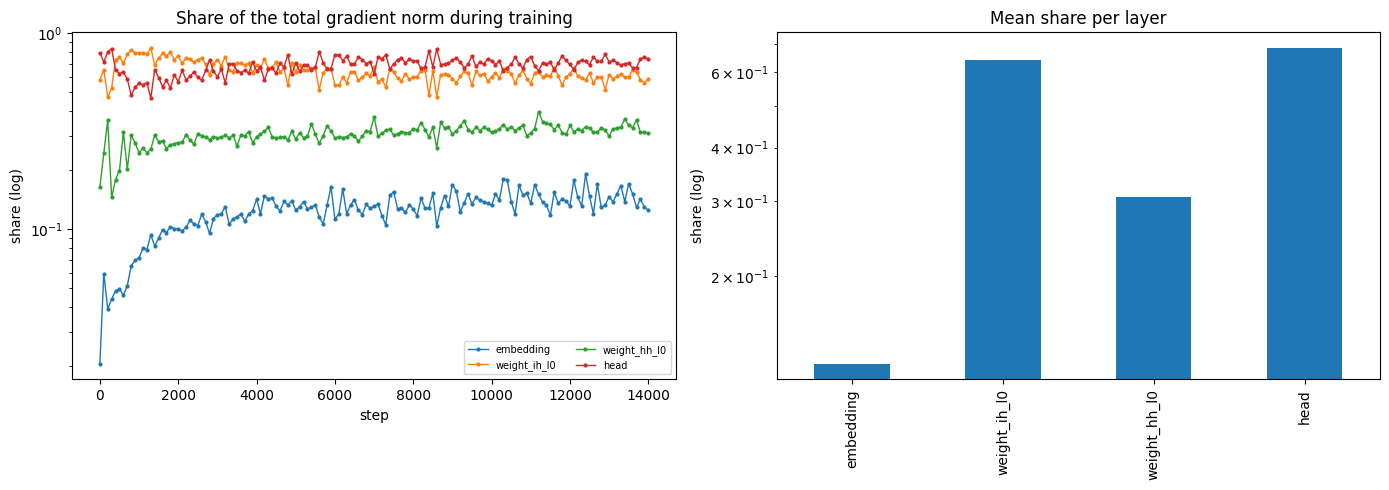

06_bilstm2_bpe


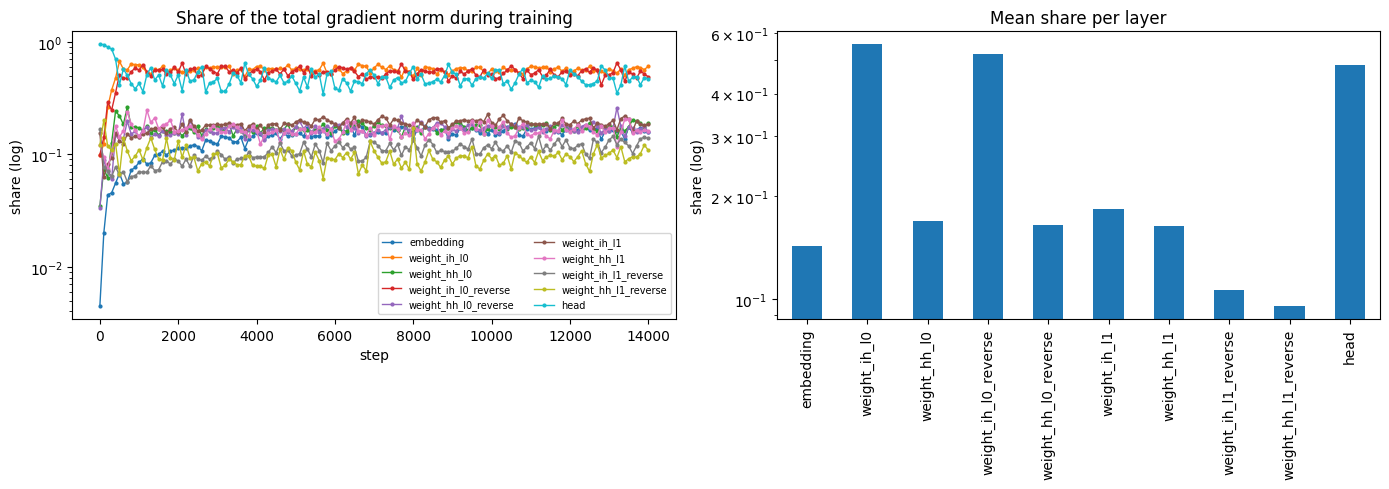

18_bilstm2_bpe_lr5e-3


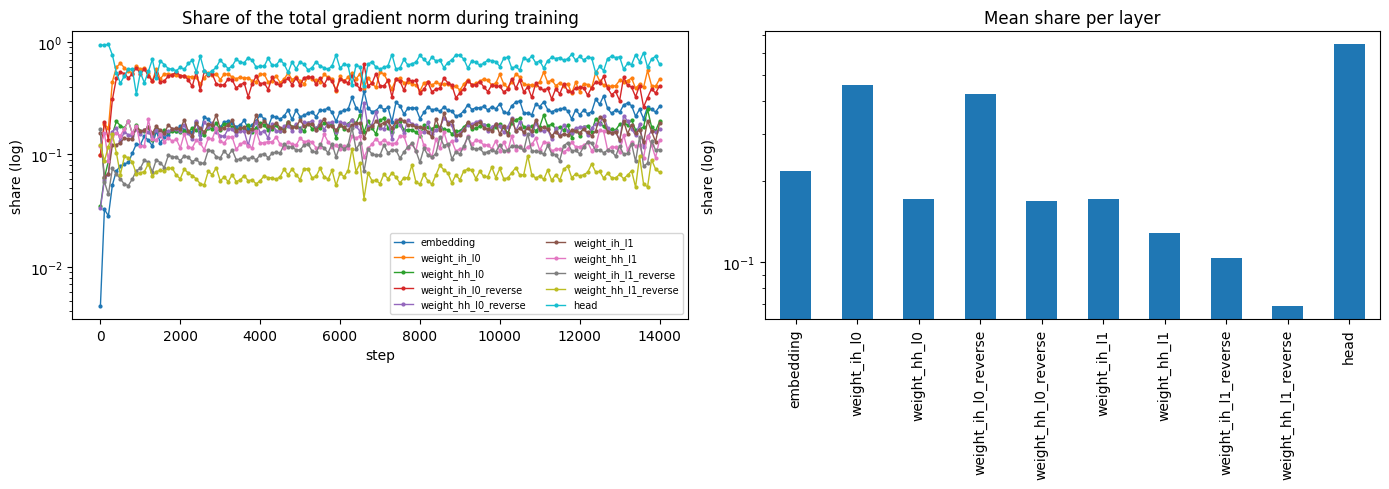

In [11]:
for name in ["01_gru_word", "06_bilstm2_bpe", "18_bilstm2_bpe_lr5e-3"]:
    print(name)
    history = pd.read_csv(GRAD_DIR / f"{name}.csv").set_index("step")
    plot_gradient_flow(history, IMG_DIR / f"gradient_flow_{name}.png")

## All runs

In [9]:
show_results().sort_values("f1_uk_valid", ascending=False)

,tokenizer,data,labels,cell,num_layers,bidirectional,hidden,optimizer,scheduler,params_M,minutes,f1_uk_valid,f1_ru_valid,f1_sample,sample_ci_low,sample_ci_high,test_locations
name,,,,,,,,,,,,,,,,,
18_bilstm2_bpe_lr5e-3,bpe,sentences,LOC+ORG+PER,lstm,2,True,256,adamw,onecycle,6.4671,19.4609,0.8955,0.9409,0.6750,0.5135,0.8182,835
11_bilstm2_word_fasttext,word,sentences,LOC+ORG+PER,lstm,2,True,256,adamw,onecycle,32.7242,16.1582,0.8893,0.9421,0.5205,0.3636,0.7170,795
13_bilstm2_bpe_adam_const,bpe,sentences,LOC+ORG+PER,lstm,2,True,256,adam,none,6.4671,19.1005,0.8890,0.9344,0.6154,0.4415,0.7576,848
14_bilstm2_bpe_adam_plateau,bpe,sentences,LOC+ORG+PER,lstm,2,True,256,adam,plateau,6.4671,19.4258,0.8888,0.9404,0.6667,0.4946,0.8056,866
19_bilstm2_bpe_posts_lr5e-3,bpe,posts,LOC+ORG+PER,lstm,2,True,256,adamw,onecycle,6.4671,20.0107,0.8885,0.9401,0.6316,0.4923,0.8077,840
06_bilstm2_bpe,bpe,sentences,LOC+ORG+PER,lstm,2,True,256,adamw,onecycle,6.4671,20.4902,0.8870,0.9357,0.6329,0.4675,0.7664,847
08_bilstm2_bpe_posts,bpe,posts,LOC+ORG+PER,lstm,2,True,256,adamw,onecycle,6.4671,18.5644,0.8856,0.9334,0.5897,0.4444,0.7797,845
04_bigru2_bpe,bpe,sentences,LOC+ORG+PER,gru,2,True,256,adamw,onecycle,5.8752,19.4350,0.8847,0.9289,0.5977,0.4415,0.7273,943
05_bilstm_bpe,bpe,sentences,LOC+ORG+PER,lstm,1,True,256,adamw,onecycle,4.8901,18.1819,0.8817,0.9327,0.6341,0.4706,0.7750,891
